# Output Parser

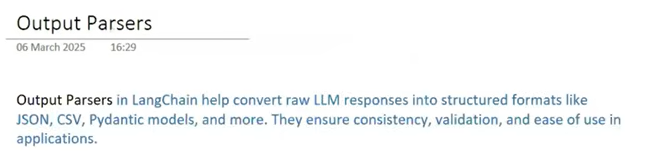

output parsers can be used with both types of llm that are 
1. can automatically structure output with (with_structure_output)
2. can not automatically structure the output

Types of output parser which we will learn
1. string output parser
2. json output parser
3. structure output parser
4. pydantic output parser

## StrOutputParser

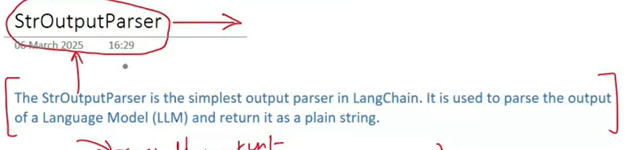

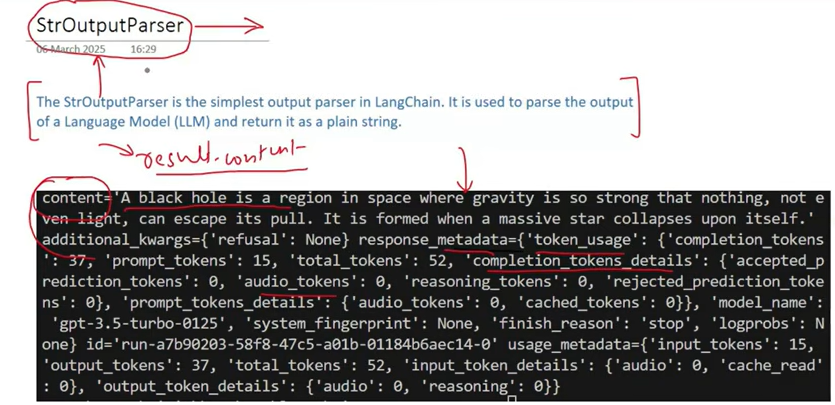

pichli video vich dekhya si 

result=model.invoke() 

pura meta deta vi dinda hai jida photo vich dikhaya ta ta aapa result.content print krde haa apna output dekhne lyi lekin agr agr strOutputParser use kraenge vich direct answer result variable vich aajana

#### we will compare result.content and StroutputParser

ek use case lita smjhn lyi

1. take any topic
2. send it to llm and ask for detailed summary
3. send result od detailed summary to llm
4. ask to generate report in 5 lines

In [10]:
from langchain_ollama import ChatOllama
from typing import TypedDict
from langchain_core.prompts import PromptTemplate
model = ChatOllama(
    model="llama3.2:1b"
)

template1=PromptTemplate(
    template='Write a detailed report on {topic}',
    input_variables=['topic']
)

template2=PromptTemplate(
    template='write a five line summary on .\n {text}',
    input_variables=['text']
)

prompt1=template1.invoke({'topic':'black hole'})
result1=model.invoke(prompt1)
prompt2=template2.invoke({'text':result1.content})
result2=model.invoke(prompt2)

print(result2.content)



Here is a five-line summary of the "Black Hole Report":

The "Black Hole Report" delves into the fascinating world of black holes, exploring their formation, properties, behavior, and potential implications for our understanding of the universe. Black holes are regions of spacetime where gravity is so strong that not even light can escape, and they are formed when massive stars collapse. There are four types of black holes, each with unique properties and formation mechanisms, and they have been detected at the centers of galaxies. Black holes have several effects on the universe, including gravitational waves, accretion disks, and ergospheres, and their study has significant potential implications for cosmology, quantum gravity, and astrometry. The report also recommends further research, collaboration, and public outreach to advance our understanding of these enigmatic objects.


### now using StrOutputParser

In [13]:
from langchain_ollama import ChatOllama
from typing import TypedDict
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
model = ChatOllama(
    model="llama3.2:1b"
)

template1=PromptTemplate(
    template='Write a detailed report on {topic}',
    input_variables=['topic']
)

template2=PromptTemplate(
    template='write a five line summary on .\n {text}',
    input_variables=['text']
)

parser=StrOutputParser()

chain=template1 | model | parser | template2 | model | parser

result=chain.invoke({'topic':'blackhole'})
print(result)

Here is a five-line summary of the Black Hole Report:

The Black Hole Report provides an in-depth overview of black holes, including their formation, structure, properties, and implications for the universe. Black holes are formed when a massive star collapses into a singularity, surrounded by an event horizon that marks the boundary of no return. Black holes have distinct properties, including mass, charge, spin, temperature, and type, and play a crucial role in galaxy evolution and cosmological parameters. Observational evidence, such as X-rays, gamma rays, radio waves, and gravitational lensing, confirms the existence of black holes. The report concludes that further research and interdisciplinary collaboration are necessary to fully understand the nature and behavior of black holes.


string output parser jo hai usse use krke hm chain bna skte hai asani se lekin agr hm parser ni use krenge to alg alg chains bnani pdegi


template1 | model 


isse parse krke fr nect chain bnegi

template2| model

### JsonOutputParser

we generally use jsonoutput parser if we want our llm result to be in json format

In [28]:
from langchain_ollama import ChatOllama
from langchain_core.output_parsers import JsonOutputParser
from langchain_core.prompts import PromptTemplate

model = ChatOllama(
    model="llama3.2:1b"
)

parser=JsonOutputParser()

template=PromptTemplate(
    template='Give me name,age and city of fictional character \n {format_instruction}',
    input_variables=[], # runtime pr define hunde hai js user input dinda hai
    partial_variables={'format_instruction':parser.get_format_instructions()} # runtime to phele define hojande hai
)

# prompt=template.format()

# result=model.invoke(prompt)
# final_result=parser.parse(result.content)

chain=template | model | parser
result=chain.invoke({})
print(result)



{'name': 'Han Solo', 'age': 55, 'city': 'Coruscant'}


json output parser doesnt allow us to enforce our own json format this is disadvantage of this parser

## StructuredOutputParser

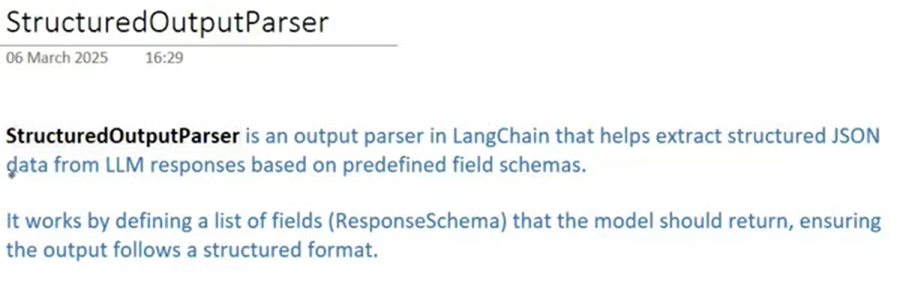

In [7]:
from langchain_ollama import ChatOllama
from langchain_core.output_parsers import JsonOutputParser
from langchain_core.prompts import PromptTemplate
from langchain_classic.output_parsers.structured import StructuredOutputParser, ResponseSchema
model = ChatOllama(
    model="llama3.2:1b"
)
schema=(
    ResponseSchema(name='fact_1',description='Fact 1 about the topic'),
    ResponseSchema(name='fact_2',description='Fact 2 about the topic'),
    ResponseSchema(name='fact_3',description='Fact 3 about the topic')
)

parser=StructuredOutputParser.from_response_schemas(schema)

template=PromptTemplate(
    template='Give 3 facts about {topic} \n {format_instruction}',
    input_variables=['topic'],
    partial_variables={'format_instruction':parser.get_format_instructions()}
)
# prompt=template.invoke({'topic':'black hole'})

# result=model.invoke(prompt)

# final_result=parser.parse(result.content)

chain=template | model | parser
final_result=chain.invoke({'topic':'black hole'})
print(final_result)

{'fact_1': 'Black holes are regions in space where the gravitational pull is so strong that nothing, including light, can escape.', 'fact_2': 'Black holes are formed when a massive star collapses in on itself and its gravity becomes so strong that it warps the fabric of spacetime around it.', 'fact_3': "The event horizon of a black hole is the point of no return around it, after which anything that crosses it will be trapped by the black hole's gravity."}


disadvantage of StructureOutputParser is that it can on enforece a response schema but does not help us in validations like if we have name,age,class we want name to be str age to be int and class to be str so structure output parser does not help

## Pydantic output parser

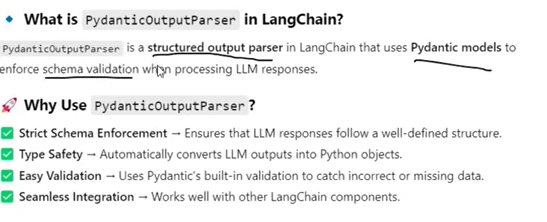

In [15]:

from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import PydanticOutputParser
from pydantic import BaseModel, Field

model = ChatOllama(
    model="llama3.2:1b",
    temperature=0
)

class Person(BaseModel):
    name: str = Field(description="Name of a person")
    age: int = Field(gt=18, description="Age of a person")
    city: str = Field(description="City of a person")

parser = PydanticOutputParser(pydantic_object=Person)

template = PromptTemplate(
    template=(
        "Generate details of one fictional {place} person.\n"
        
        "{format_instruction}"
    ),
    input_variables=["place"],
    partial_variables={
        "format_instruction": parser.get_format_instructions()
    }
)

chain = template | model | parser

result = chain.invoke({"place": "Indian"})

print(result)


name='Rohan Kumar' age=32 city='Mumbai'
